# 第 2 章 概率论基础：蒙特卡罗的两大理论支柱 — 代码实验

对照教材：Dunn & Shultis《Exploring Monte Carlo Methods》Ch.2 与附录 B/C；Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》§1.2。

约定：随机种子 2024；所有插图保存到 `docs/mc/images/ch02/`，编号 `out-2-M` 与笔记图注一一对应。

六个实验（顺序与笔记小节一致）：① Bayes/HIV 检测（S&M 习题 13）；② 样本方差无偏性 E[s²]=σ²；③ 大数定律（骰子样本均值收敛 + 误差沿 σ/√N）；④ Chebyshev 边界 vs 实际频率；⑤ 中心极限定理（均匀样本和的标准化，n=1,2,5,30）；⑥ hit-or-miss 与 sample-mean 的方差账。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch02")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2024)   # 全章共用一个随机数流
print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 Bayes 公式：HIV 检测（S&M 习题 13，笔记 §2.1）

患病率 3%，试剂灵敏度 98%、特异度 98%（S&M："98% accurate both ways"）。模拟 100 万人：阳性的人里真患病的比例是多少？直觉的 98% 是错的——Bayes 公式给出约 60%。

四格计数：真阳性 29294，假阳性 19376，漏检 612，真阴性 950718
模拟 P(患病|阳性) = 29294/(29294+19376) = 0.6019
Bayes 公式       = 0.0294/(0.0294+0.0194) = 0.6025


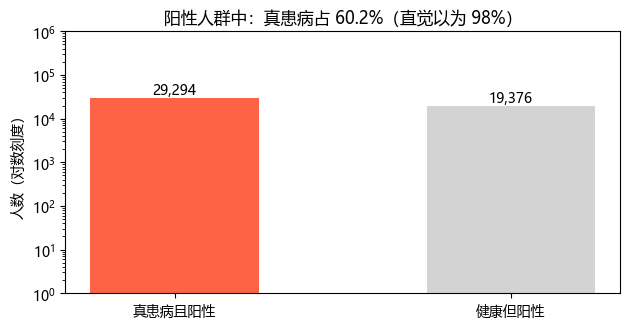

In [2]:
Pop = 1_000_000
prev, sens, spec = 0.03, 0.98, 0.98
sick = rng.random(Pop) < prev                                       # 是否真患病
pos  = np.where(sick, rng.random(Pop) < sens, rng.random(Pop) < 1 - spec)  # 是否测出阳性

tp, fp = int((sick & pos).sum()), int((~sick & pos).sum())          # 真阳性 / 假阳性
fn, tn = int((sick & ~pos).sum()), int((~sick & ~pos).sum())
ppv = tp / (tp + fp)
theory = prev * sens / (prev * sens + (1 - prev) * (1 - spec))
print(f"四格计数：真阳性 {tp}，假阳性 {fp}，漏检 {fn}，真阴性 {tn}")
print(f"模拟 P(患病|阳性) = {tp}/({tp}+{fp}) = {ppv:.4f}")
print(f"Bayes 公式       = {prev*sens:.4f}/({prev*sens:.4f}+{(1-prev)*(1-spec):.4f}) = {theory:.4f}")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
bars = ax.bar(["真患病且阳性", "健康但阳性"], [tp, fp], color=["tomato", "lightgray"], width=0.5)
for b, v in zip(bars, [tp, fp]):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}", ha="center", va="bottom", fontsize=10)
ax.set_yscale("log"); ax.set_ylim(1, 1e6); ax.set_ylabel("人数（对数刻度）")
ax.set_title(f"阳性人群中：真患病占 {ppv*100:.1f}%（直觉以为 98%）")
fig.tight_layout(); save(fig, "out-2-1.png"); plt.show()

## 实验 2 样本方差的无偏性 E[s²] = σ²（笔记 §2.2）

取指数分布（$\mu=2$，$\sigma^2=4$）。重复 20 000 次"抽 n=10 算样本方差"：除 $N-1$ 的 $s^2$ 应平均等于 4；除 $N$ 的版本应平均等于 $4\times 9/10=3.6$（系统低估 $(N-1)/N$ 倍）。

E[s²(N−1)] = 4.0210（理论 σ² = 4）
E[s²(N)]   = 3.6189（理论 σ²(N−1)/N = 3.60）


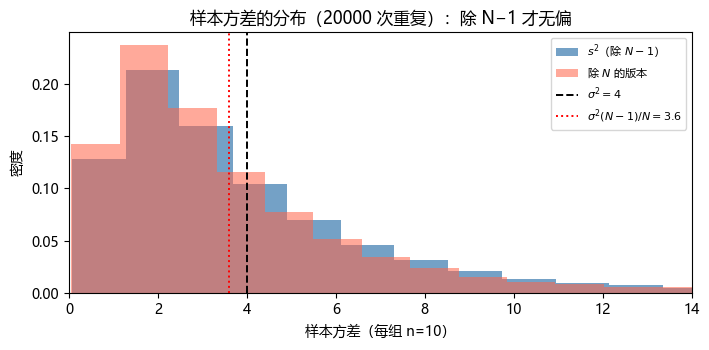

In [3]:
reps, n = 20_000, 10
X = rng.exponential(2.0, size=(reps, n))     # 指数分布，μ=2，σ²=4
s2_u = X.var(axis=1, ddof=1)                 # 除 N−1：无偏版本
s2_b = X.var(axis=1, ddof=0)                 # 除 N：有偏版本
print(f"E[s²(N−1)] = {s2_u.mean():.4f}（理论 σ² = 4）")
print(f"E[s²(N)]   = {s2_b.mean():.4f}（理论 σ²(N−1)/N = {4*(n-1)/n:.2f}）")

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.hist(s2_u, bins=60, density=True, color="steelblue", alpha=0.75, label=r"$s^2$（除 $N-1$）")
ax.hist(s2_b, bins=60, density=True, color="tomato", alpha=0.55, label=r"除 $N$ 的版本")
ax.axvline(4.0, color="k", ls="--", lw=1.4, label=r"$\sigma^2=4$")
ax.axvline(3.6, color="r", ls=":", lw=1.4, label=r"$\sigma^2(N-1)/N=3.6$")
ax.set_xlim(0, 14); ax.set_xlabel("样本方差（每组 n=10）"); ax.set_ylabel("密度")
ax.set_title(f"样本方差的分布（{reps} 次重复）：除 N−1 才无偏")
ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "out-2-2.png"); plt.show()

## 实验 3 大数定律：骰子的样本均值（笔记 §2.5）

掷一颗均匀骰子，总体均值 $\mu=3.5$、方差 $\sigma^2=35/12$（推导见笔记 §2.3）。看累积样本均值 $\bar x_N$ 如何收敛，以及误差是否贴着 $\sigma/\sqrt N$（1 个标准误差带）上下穿越。

总体 μ = 3.5，σ = 1.7078
N =    100: 样本均值 = 3.2900，|误差| = 0.2100，σ/√N = 0.1708
N =  10000: 样本均值 = 3.4930，|误差| = 0.0070，σ/√N = 0.0171
N = 100000: 样本均值 = 3.4994，|误差| = 0.0006，σ/√N = 0.0054


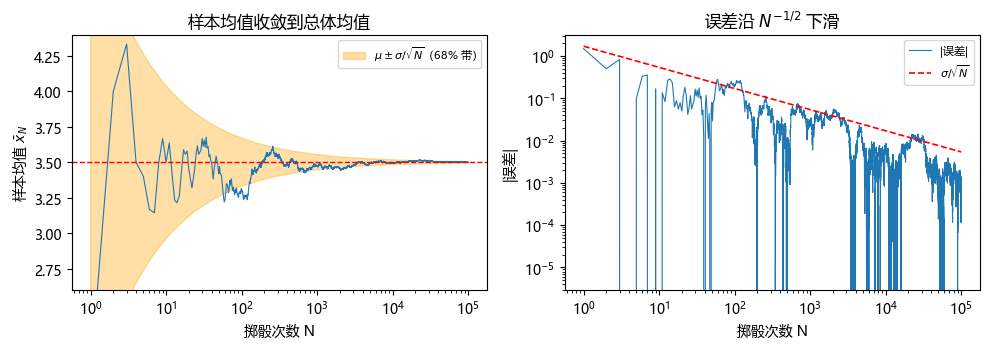

In [4]:
N = 100_000
rolls = rng.integers(1, 7, N)                       # 掷骰子 N 次（1~6 等可能）
run_mean = np.cumsum(rolls) / np.arange(1, N + 1)   # 累积样本均值

mu, var = 3.5, 35.0 / 12.0                          # 总体均值与方差
print(f"总体 μ = 3.5，σ = {math.sqrt(var):.4f}")
for n in [100, 10_000, 100_000]:
    print(f"N = {n:>6}: 样本均值 = {run_mean[n-1]:.4f}，|误差| = {abs(run_mean[n-1]-mu):.4f}，σ/√N = {math.sqrt(var/n):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
nn = np.arange(1, N + 1)
band = np.sqrt(var / nn)
ax[0].plot(nn, run_mean, lw=0.8)
ax[0].axhline(mu, color="r", ls="--", lw=1)
ax[0].fill_between(nn, mu - band, mu + band, color="orange", alpha=0.35, label=r"$\mu\pm\sigma/\sqrt{N}$（68% 带）")
ax[0].set_xscale("log"); ax[0].set_ylim(2.6, 4.4)
ax[0].set_xlabel("掷骰次数 N"); ax[0].set_ylabel(r"样本均值 $\bar x_N$")
ax[0].set_title("样本均值收敛到总体均值"); ax[0].legend(fontsize=8, loc="upper right")
ax[1].loglog(nn, np.abs(run_mean - mu), lw=0.8, label="|误差|")
ax[1].loglog(nn, band, "r--", lw=1.2, label=r"$\sigma/\sqrt{N}$")
ax[1].set_xlabel("掷骰次数 N"); ax[1].set_ylabel("|误差|")
ax[1].set_title(r"误差沿 $N^{-1/2}$ 下滑"); ax[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "out-2-3.png"); plt.show()

## 实验 4 Chebyshev 边界 vs 实际频率（笔记 §2.5）

Chebyshev：$\Pr(|X-\mu|\ge k\sigma)\le 1/k^2$，对**任何**有有限方差的分布成立——所以必然保守。对指数分布（$\mu=\sigma=1$）与均匀分布 $U(0,1)$ 实测 $k=1,2,3,4$ 的频率，与 $1/k^2$ 对照。

k          1        2        3        4
1/k²    1.0000  0.2500  0.1111  0.0625   （Chebyshev 上界）
指数    0.1357  0.0498  0.0184  0.0067   （理论 e^{-(1+k)}：0.1353/0.0498/0.0183/0.0067）
均匀    0.4242  0.0000  0.0000  0.0000   （k=1 理论 0.4226；k≥2 恒为 0）


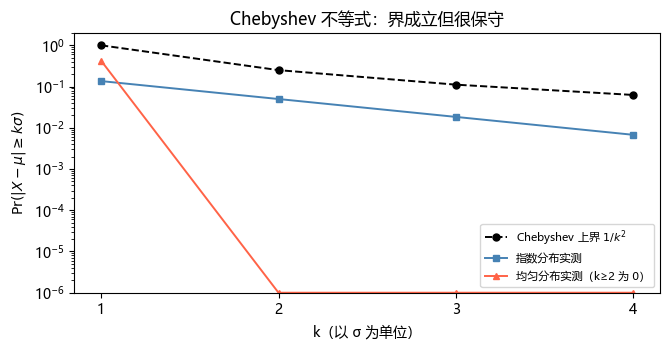

In [5]:
M = 400_000
Xe = rng.exponential(1.0, M)                 # 指数：μ = 1，σ = 1
Xu = rng.random(M)                           # 均匀 U(0,1)：μ = 0.5，σ = √(1/12)
ks = np.array([1, 2, 3, 4])
freq_e = np.array([np.mean(np.abs(Xe - 1.0) >= k) for k in ks])
freq_u = np.array([np.mean(np.abs(Xu - 0.5) >= k / math.sqrt(12)) for k in ks])
bound = 1.0 / ks**2
print("k          1        2        3        4")
print("1/k²    " + "  ".join(f"{b:.4f}" for b in bound) + "   （Chebyshev 上界）")
print("指数    " + "  ".join(f"{f:.4f}" for f in freq_e) + "   （理论 e^{-(1+k)}：0.1353/0.0498/0.0183/0.0067）")
print("均匀    " + "  ".join(f"{f:.4f}" for f in freq_u) + "   （k=1 理论 0.4226；k≥2 恒为 0）")

fig, ax = plt.subplots(figsize=(6.8, 3.6))
ax.semilogy(ks, bound, "k--o", lw=1.4, ms=5, label=r"Chebyshev 上界 $1/k^2$")
ax.semilogy(ks, freq_e, "s-", color="steelblue", lw=1.4, ms=5, label="指数分布实测")
ax.semilogy(ks, np.maximum(freq_u, 1e-6), "^-", color="tomato", lw=1.4, ms=5, label="均匀分布实测（k≥2 为 0）")
ax.set_xticks(ks); ax.set_xlabel(r"k（以 σ 为单位）"); ax.set_ylabel(r"$\mathrm{Pr}(|X-\mu|\geq k\sigma)$")
ax.set_title("Chebyshev 不等式：界成立但很保守"); ax.legend(fontsize=8); ax.set_ylim(1e-6, 2)
fig.tight_layout(); save(fig, "out-2-4.png"); plt.show()

## 实验 5 中心极限定理：均匀样本和的标准化（笔记 §2.6）

$U_i\sim U(0,1)$，$S_n=\sum U_i$。标准化 $Z_n=(S_n-n/2)/\sqrt{n/12}$ 的分布随 $n$ 滑向标准正态。均匀分布的超额峰度为 $-1.2$，可以证明 $n$ 个独立和的超额峰度恰为 $-1.2/n$——用峰度定量检验"越来越正态"。

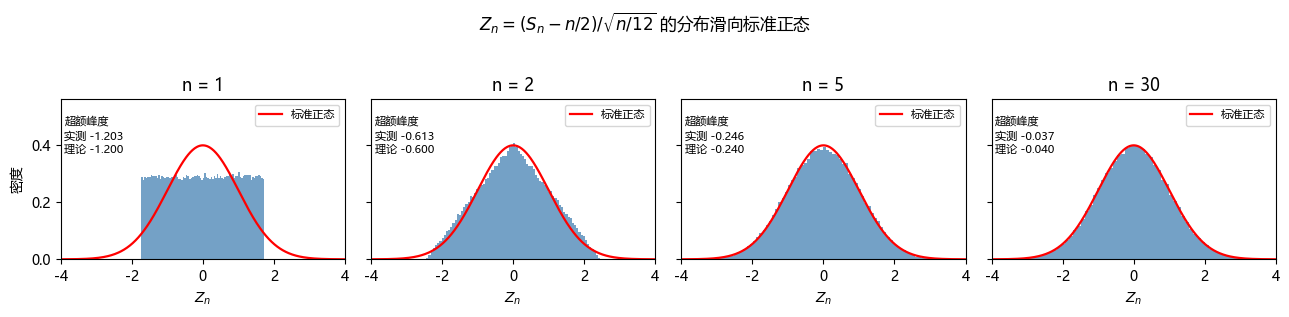

In [6]:
M = 200_000
ns = [1, 2, 5, 30]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.0), sharey=True)
xx = np.linspace(-4, 4, 400)
pdf_norm = np.exp(-xx**2 / 2) / np.sqrt(2 * np.pi)
for k, n in enumerate(ns):
    Sn = rng.random((M, n)).sum(axis=1)          # n 个 U(0,1) 之和
    Z = (Sn - n / 2) / math.sqrt(n / 12.0)       # 标准化：均值 0、方差 1
    m4 = np.mean((Z - Z.mean())**4); kurt = m4 / Z.var()**2 - 3
    axes[k].hist(Z, bins=80, density=True, color="steelblue", alpha=0.75)
    axes[k].plot(xx, pdf_norm, "r-", lw=1.6, label="标准正态")
    axes[k].set_xlim(-4, 4); axes[k].set_ylim(0, 0.56)
    axes[k].set_title(f"n = {n}")
    axes[k].text(-3.9, 0.50, f"超额峰度\n实测 {kurt:+.3f}\n理论 {-1.2/n:+.3f}",
                 fontsize=8, va="top")
    axes[k].set_xlabel(r"$Z_n$"); axes[k].legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("密度")
fig.suptitle(r"$Z_n=(S_n-n/2)/\sqrt{n/12}$ 的分布滑向标准正态", y=1.04)
fig.tight_layout(); save(fig, "out-2-5.png"); plt.show()

## 实验 6 两种求积法的方差账（笔记 §2.7）

靶子 $I=\int_0^1 e^{-x^2}\,dx$（真值 0.7468241）。理论（笔记 §2.7）：
$\sigma^2_{sm}=[\int_0^1 g^2dx-I^2]/N=0.04040/N$，$\sigma^2_{hm}=[M(b-a)I-I^2]/N=0.18908/N$（$M=1$），
标准差之比 $\approx 2.163$。用 2000 个 super-experiment（各 1000 条 history）实测验证。

理论：σ²_sm = 0.04040/N，σ²_hm = 0.18908/N，方差比 = 4.680，标准差比 = 2.163
实测：s(hm) = 0.01367，s(sm) = 0.00649，标准差比 = 2.105
实测均值：hit-or-miss = 0.74684，sample-mean = 0.74695（真值 0.74682）


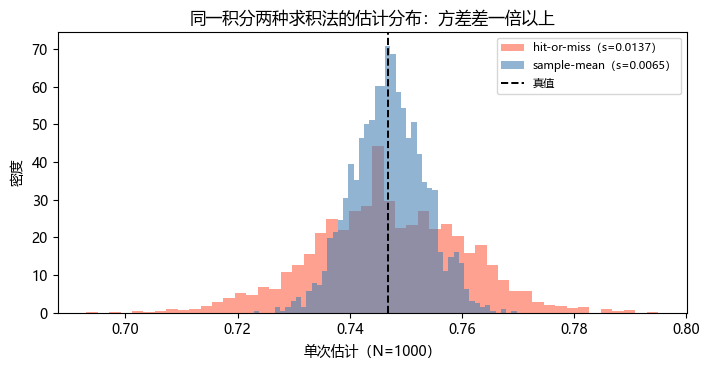

In [7]:
B, N = 2000, 1000          # 2000 个 super-experiment，每个 1000 条 history
g = lambda x: np.exp(-x * x)
exact = 0.7468241328124271

x1, y1 = rng.random((B, N)), rng.random((B, N))
hm = (y1 <= g(x1)).mean(axis=1)          # hit-or-miss：容器 [0,1]×[0,1]，面积 1
x2 = rng.random((B, N))
sm = g(x2).mean(axis=1)                  # sample-mean：连续分数

I2 = math.sqrt(math.pi / 8) * math.erf(math.sqrt(2))     # ∫₀¹ e^{-2x²} dx
v_sm = I2 - exact**2
v_hm = 1.0 * exact - exact**2
print(f"理论：σ²_sm = {v_sm:.5f}/N，σ²_hm = {v_hm:.5f}/N，方差比 = {v_hm/v_sm:.3f}，标准差比 = {math.sqrt(v_hm/v_sm):.3f}")
print(f"实测：s(hm) = {hm.std(ddof=1):.5f}，s(sm) = {sm.std(ddof=1):.5f}，标准差比 = {hm.std(ddof=1)/sm.std(ddof=1):.3f}")
print(f"实测均值：hit-or-miss = {hm.mean():.5f}，sample-mean = {sm.mean():.5f}（真值 {exact:.5f}）")

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.hist(hm, bins=50, density=True, color="tomato", alpha=0.6, label=f"hit-or-miss（s={hm.std(ddof=1):.4f}）")
ax.hist(sm, bins=50, density=True, color="steelblue", alpha=0.6, label=f"sample-mean（s={sm.std(ddof=1):.4f}）")
ax.axvline(exact, color="k", ls="--", lw=1.4, label="真值")
ax.set_xlabel(r"单次估计（N=1000）"); ax.set_ylabel("密度")
ax.set_title("同一积分两种求积法的估计分布：方差差一倍以上")
ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "out-2-6.png"); plt.show()